<a href="https://colab.research.google.com/github/dimi-kri/ML-Ergasia5/blob/main/Ergasia5_Decision_Trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Εργασία 5 – Δέντρα Απόφασης


## Βιβλιοθήκες

In [24]:
!pip install -q dtreeviz

In [25]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dtreeviz

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

seed = 0

## Ερώτημα 1 – Φόρτωση δεδομένων, ιστογράμματα και ελλιπείς τιμές


In [26]:
df = pd.read_csv('water_potability.csv')
print('Διαστάσεις:', df.shape)
df.head()

Διαστάσεις: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


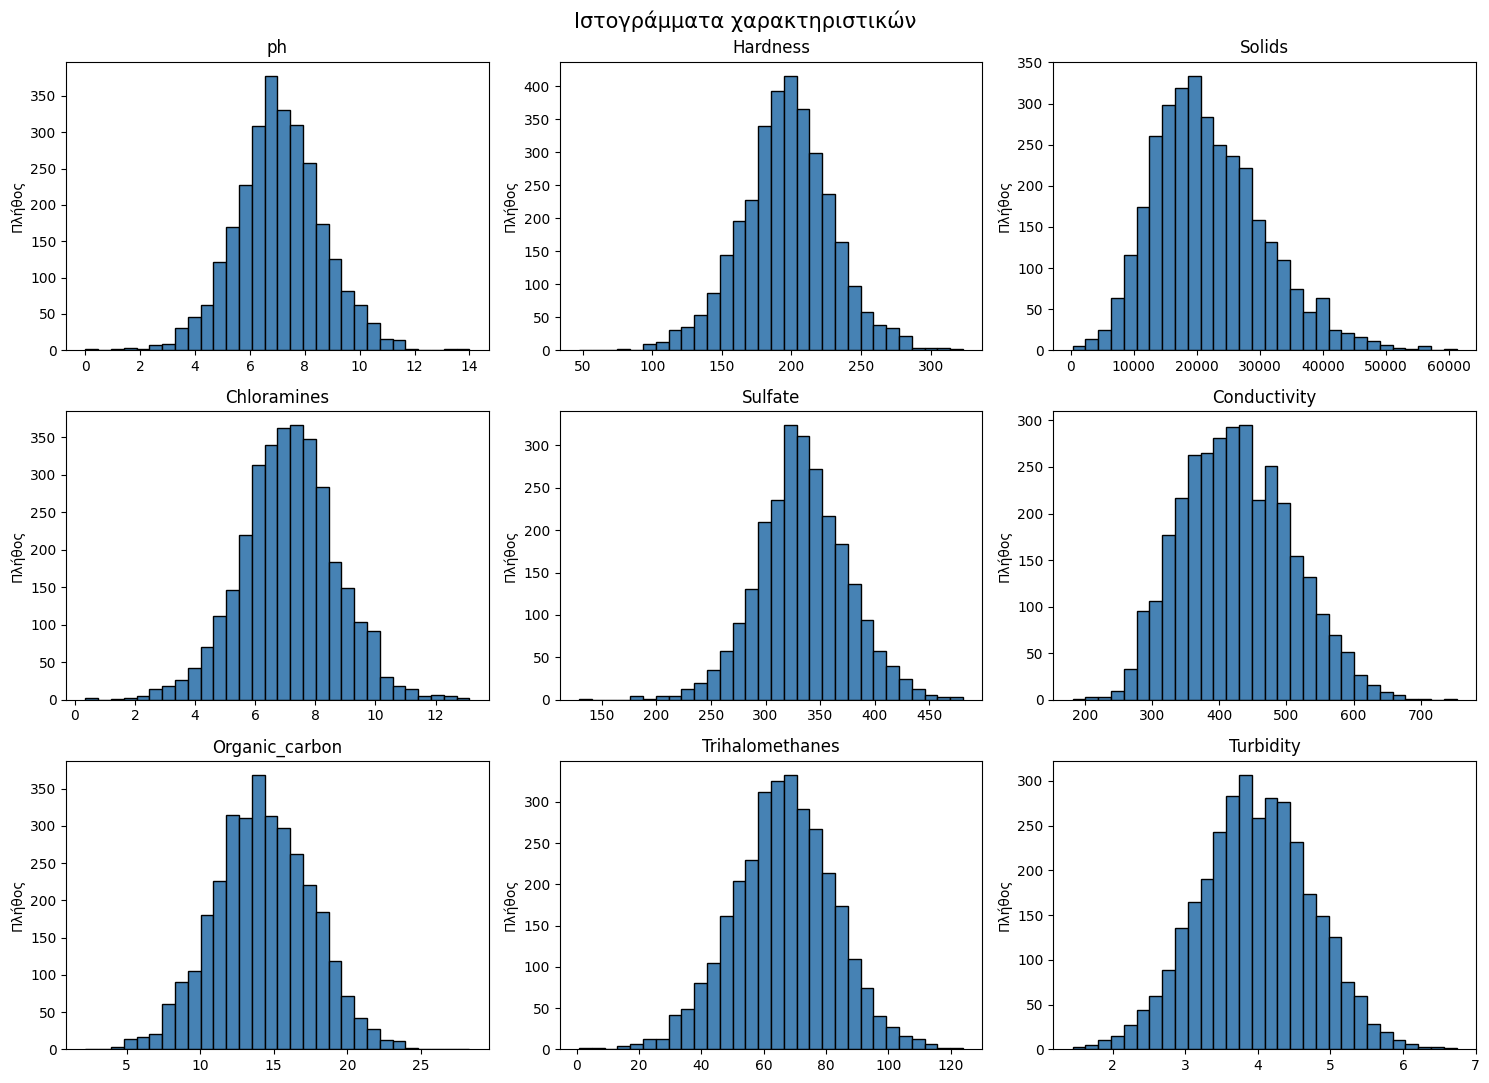

In [27]:
features = df.columns.drop('Potability')

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='black')
    ax.set_title(col)
    ax.set_ylabel('Πλήθος')
plt.suptitle('Ιστογράμματα χαρακτηριστικών', fontsize=15)
plt.tight_layout()
plt.show()

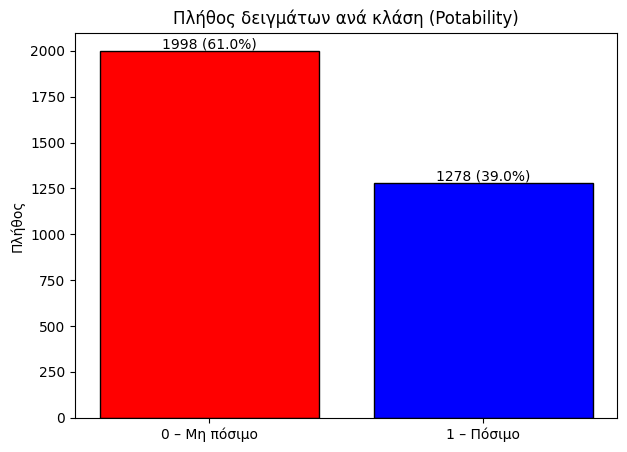

In [28]:
counts = df['Potability'].value_counts().sort_index()
percent = df['Potability'].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(['0 – Μη πόσιμο', '1 – Πόσιμο'], counts, color=['red', 'blue'], edgecolor='black')
for bar, c, p in zip(bars, counts, percent):
    plt.text(bar.get_x() + bar.get_width() / 2, c, f'{c} ({p:.1f}%)', ha='center', va='bottom')
plt.title('Πλήθος δειγμάτων ανά κλάση (Potability)')
plt.ylabel('Πλήθος')
plt.show()

In [29]:
missing = pd.DataFrame({'Ελλιπείς τιμές': df.isna().sum(),
                        'Ποσοστό (%)': (df.isna().mean() * 100).round(2)})
missing

,Ελλιπείς τιμές,Ποσοστό (%)
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00


### Συμπέρασμα

- **Ελλιπείς τιμές** υπάρχουν σε 3 χαρακτηριστικά: ph (491), Sulfate (781) και Trihalomethanes (162). Τα υπόλοιπα είναι πλήρη.
- **Κλάσεις:** το **61%** των δειγμάτων είναι μη πόσιμο νερό και το **39%** πόσιμο. Το dataset δεν είναι τελείως ισορροπημένο.
- Τα περισσότερα χαρακτηριστικά έχουν σχήμα «καμπάνας» (περίπου κανονική κατανομή). Το Solids είναι λίγο πιο απλωμένο προς τα δεξιά.

## Ερώτημα 2 – pH και πόσιμο νερό


In [30]:
ph = df['ph'].dropna()
ph_group = pd.Series(np.select([ph < 6.5, ph <= 8.5], ['pH < 6.5', '6.5 ≤ pH ≤ 8.5'], '8.5 < pH'), index=ph.index)

ph_table = pd.crosstab(ph_group, df.loc[ph.index, 'Potability'], normalize='index') * 100
ph_table.columns = ['Μη πόσιμο (%)', 'Πόσιμο (%)']
ph_table['Πλήθος δειγμάτων'] = ph_group.value_counts()
ph_table.rename_axis(None).loc[['pH < 6.5', '6.5 ≤ pH ≤ 8.5', '8.5 < pH']].round(1)

,Μη πόσιμο (%),Πόσιμο (%),Πλήθος δειγμάτων
pH < 6.5,63.2,36.8,968
6.5 ≤ pH ≤ 8.5,56.1,43.9,1328
8.5 < pH,66.9,33.1,489


### Σε τι βαθμό επαληθεύεται;

**Μόνο σε μικρό βαθμό.** Στην περιοχή του ΠΟΥ (6.5–8.5) το ποσοστό πόσιμου νερού είναι πράγματι το μεγαλύτερο (~44%), ενώ έξω από αυτήν πέφτει στο ~37% (pH < 6.5) και στο ~33% (pH > 8.5).

Όμως:
- ακόμα και μέσα στην περιοχή του ΠΟΥ, τα περισσότερα δείγματα (56%) είναι μη πόσιμα,
- έξω από τα όρια (pH < 6.5 ή pH > 8.5), περίπου το 35% των νερών είναι πόσιμο, ενώ σύμφωνα με τον ΠΟΥ θα έπρεπε να είναι 0%.

Άρα το σωστό pH **δεν αρκεί** για να είναι το νερό πόσιμο. Η πόσιμότητα εξαρτάται και από τα υπόλοιπα χαρακτηριστικά.

## Ερώτημα 3 – Scatter plot pH και Chloramines


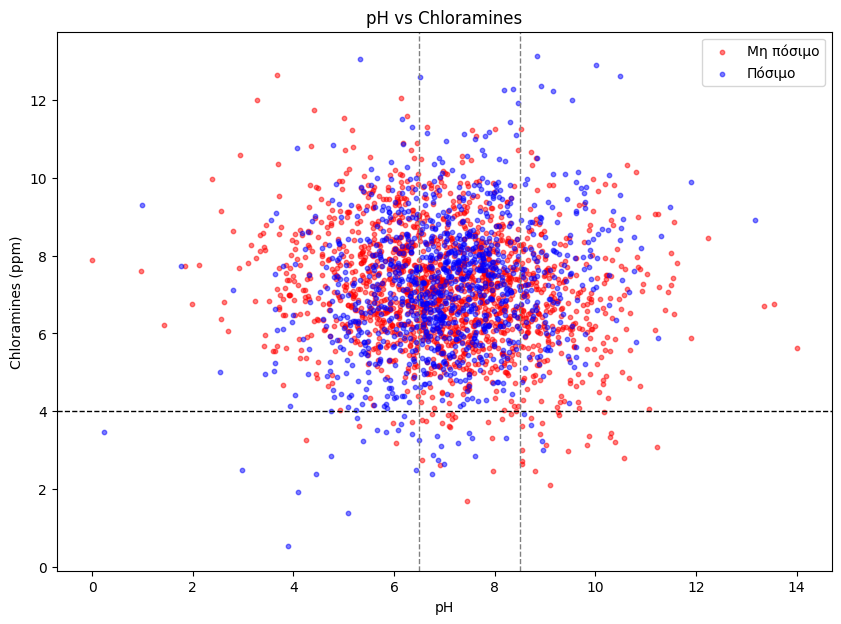

In [31]:
potable = df[df['Potability'] == 1]
not_potable = df[df['Potability'] == 0]

plt.figure(figsize=(10, 7))
plt.scatter(not_potable['ph'], not_potable['Chloramines'], c='red', s=10, alpha=0.5, label='Μη πόσιμο')
plt.scatter(potable['ph'], potable['Chloramines'], c='blue', s=10, alpha=0.5, label='Πόσιμο')
plt.axhline(4, color='black', linestyle='--', linewidth=1)
plt.axvline(6.5, color='gray', linestyle='--', linewidth=1)
plt.axvline(8.5, color='gray', linestyle='--', linewidth=1)
plt.xlabel('pH')
plt.ylabel('Chloramines (ppm)')
plt.title('pH vs Chloramines')
plt.legend()
plt.show()

### Συμπέρασμα

Οι μπλε (πόσιμο) και οι κόκκινες (μη πόσιμο) τελείες είναι εντελώς ανακατεμένες. Δεν υπάρχει καμία γραμμή ή περιοχή που να χωρίζει τις δύο κλάσεις, άρα τα δείγματα δεν είναι διαχωρίσιμα με αυτά τα δύο χαρακτηριστικά.

Επιπλέον, σχεδόν όλα τα δείγματα έχουν χλωραμίνη πάνω από 4 ppm, ακόμα και τα πόσιμα. Άρα ούτε το όριο του ΠΟΥ για τη χλωραμίνη επαληθεύεται στα δεδομένα. Αυτό δείχνει ότι το πρόβλημα είναι δύσκολο και δεν περιμένουμε πολύ υψηλή ακρίβεια από το μοντέλο.

## Ερώτημα 4 – Συμπλήρωση ελλιπών τιμών

Συμπληρώνουμε τις ελλιπείς τιμές των ph, Sulfate και Trihalomethanes με τη μέση τιμή κάθε στήλης.

Δεν χρησιμοποιούμε σταθερά 0, γιατί η στήλη ph έχει ήδη ένα δείγμα με τιμή 0 και δεν θα ξεχωρίζαμε ποιο είναι πραγματικό και ποιο συμπληρωμένο. Επιπλέον, το pH 0 είναι εξαιρετικά όξινο, οπότε θα έδινε λάθος πληροφορία στο δέντρο. Με τη μέση τιμή υποθέτουμε την πιο συνηθισμένη τιμή.

In [32]:
print('Τιμές pH ίσες με 0:', (df['ph'] == 0).sum())

for col in ['ph', 'Sulfate', 'Trihalomethanes']:
    df[col] = df[col].fillna(df[col].mean())

print('Ελλιπείς τιμές μετά τη συμπλήρωση:', df.isna().sum().sum())

Τιμές pH ίσες με 0: 1
Ελλιπείς τιμές μετά τη συμπλήρωση: 0


## Ερώτημα 5 – Numpy arrays και διαχωρισμός train-test (90-10%)

In [33]:
x = df.drop(columns='Potability').to_numpy()
y = df['Potability'].to_numpy()

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1, stratify=y, random_state=seed)
print('Train:', x_train.shape, ' Test:', x_test.shape)

Train: (2948, 9)  Test: (328, 9)


## Ερώτημα 6 – Δέντρο Απόφασης



In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

tree = DecisionTreeClassifier(random_state=seed)
tree.fit(x_train, y_train)

pd.DataFrame({
    'Accuracy': [accuracy_score(y_train, tree.predict(x_train)),
                 cross_val_score(DecisionTreeClassifier(random_state=seed), x_train, y_train, cv=cv).mean(),
                 accuracy_score(y_test, tree.predict(x_test))]
}, index=['Train', 'Validation (5-fold CV)', 'Test']).round(4)

,Accuracy
Train,1.0000
Validation (5-fold CV),0.5817
Test,0.6280


### Συμπέρασμα

Στο train το δέντρο έχει ακρίβεια 100%, ενώ στο validation και στο test μόνο ~58–63%. Αυτό είναι overfitting: χωρίς κανένα όριο, το δέντρο μεγαλώνει μέχρι να μάθει απ' έξω κάθε δείγμα του train και δεν γενικεύει σε νέα δείγματα.

## Ερώτημα 7 – Δοκιμή υπερπαραμέτρων



In [35]:
grid = itertools.product(['gini', 'entropy'], [None, 3, 5], [2, 5], [1, 2], [None, 'sqrt'], [0, 0.01])

rows = []
for criterion, max_depth, min_split, min_leaf, max_feat, alpha in grid:
    params = dict(criterion=criterion, max_depth=max_depth, min_samples_split=min_split,
                  min_samples_leaf=min_leaf, max_features=max_feat, ccp_alpha=alpha, random_state=seed)
    model = DecisionTreeClassifier(**params)
    cv_acc = cross_val_score(model, x_train, y_train, cv=cv).mean()
    model.fit(x_train, y_train)
    p_train, p_test = model.predict(x_train), model.predict(x_test)
    rows.append({
        'criterion': criterion, 'max_depth': max_depth, 'min_samples_split': min_split,
        'min_samples_leaf': min_leaf, 'max_features': max_feat, 'ccp_alpha': alpha,
        'CV Accuracy': cv_acc,
        'Train Accuracy': accuracy_score(y_train, p_train),
        'Train Precision': precision_score(y_train, p_train, zero_division=0),
        'Train Recall': recall_score(y_train, p_train),
        'Test Accuracy': accuracy_score(y_test, p_test),
        'Test Precision': precision_score(y_test, p_test, zero_division=0),
        'Test Recall': recall_score(y_test, p_test)
    })

results = pd.DataFrame(rows)
results['max_depth'] = results['max_depth'].astype(object).where(results['max_depth'].notna(), 'None')
results['max_features'] = results['max_features'].fillna('None')
pd.set_option('display.max_rows', 100)
results.round(4)

,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV Accuracy,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
0,gini,None,2,1,None,0.00,0.5817,1.0000,1.0000,1.0000,0.6280,0.5221,0.5547
1,gini,None,2,1,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
2,gini,None,2,1,sqrt,0.00,0.5787,1.0000,1.0000,1.0000,0.5610,0.4437,0.4922
3,gini,None,2,1,sqrt,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
4,gini,None,2,2,None,0.00,0.5967,0.9525,0.9755,0.9009,0.6189,0.5124,0.4844
5,gini,None,2,2,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
6,gini,None,2,2,sqrt,0.00,0.5974,0.9311,0.9730,0.8470,0.5854,0.4615,0.3750
7,gini,None,2,2,sqrt,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
8,gini,None,5,1,None,0.00,0.5950,0.9718,0.9717,0.9557,0.6220,0.5147,0.5469
9,gini,None,5,1,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000


In [36]:
print('Καλύτερος συνδυασμός με βάση το CV Accuracy:')
results.loc[[results['CV Accuracy'].idxmax()]].round(4)

Καλύτερος συνδυασμός με βάση το CV Accuracy:


,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV Accuracy,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
16,gini,3.0,2,1,None,0.0,0.6398,0.6608,0.7259,0.2096,0.6037,0.4706,0.125


### Συμπέρασμα

- Τα δέντρα χωρίς όριο βάθους (max_depth = None) έχουν train accuracy κοντά στο 100% αλλά πολύ χαμηλότερη στο test: κάνουν overfitting.
- Με max_depth = 3 ή 5 η διαφορά train–test μικραίνει πολύ, δηλαδή το δέντρο γενικεύει καλύτερα.
- Με ccp_alpha = 0.01 το κλάδεμα είναι τόσο έντονο που σε όλους τους συνδυασμούς το δέντρο μένει με έναν μόνο κόμβο και προβλέπει πάντα «μη πόσιμο». Γι' αυτό το accuracy είναι 0.61 και το recall 0.
- Το cross-validation επιλέγει δέντρο βάθους 3, ενώ το test ευνοεί λίγο τα πιο βαθιά δέντρα. Οι διαφορές όμως είναι μικρές: όλα τα δέντρα μένουν γύρω στο 60–63%, όπως περιμέναμε από το scatter plot του Ερωτήματος 3.

## Ερώτημα 8 – Το καλύτερο δέντρο με max_depth = 5 και οπτικοποίηση με dtreeviz

In [37]:
depth5 = results[results['max_depth'] == 5]
best5 = depth5.loc[depth5['Test Accuracy'].idxmax()]
print('Καλύτερος συνδυασμός με max_depth = 5:')
best5.to_frame().T.round(4)

Καλύτερος συνδυασμός με max_depth = 5:


,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV Accuracy,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
46,gini,5.0,5,2,sqrt,0.0,0.625168,0.662483,0.70557,0.231304,0.621951,0.555556,0.15625


In [38]:
def get_params(row):
    return dict(criterion=row['criterion'],
                max_depth=None if row['max_depth'] == 'None' else int(row['max_depth']),
                min_samples_split=int(row['min_samples_split']),
                min_samples_leaf=int(row['min_samples_leaf']),
                max_features=None if row['max_features'] == 'None' else row['max_features'],
                ccp_alpha=float(row['ccp_alpha']),
                random_state=seed)

tree8 = DecisionTreeClassifier(**get_params(best5))
tree8.fit(x_train, y_train)
print('Test accuracy:', round(accuracy_score(y_test, tree8.predict(x_test)), 4))

Test accuracy: 0.622


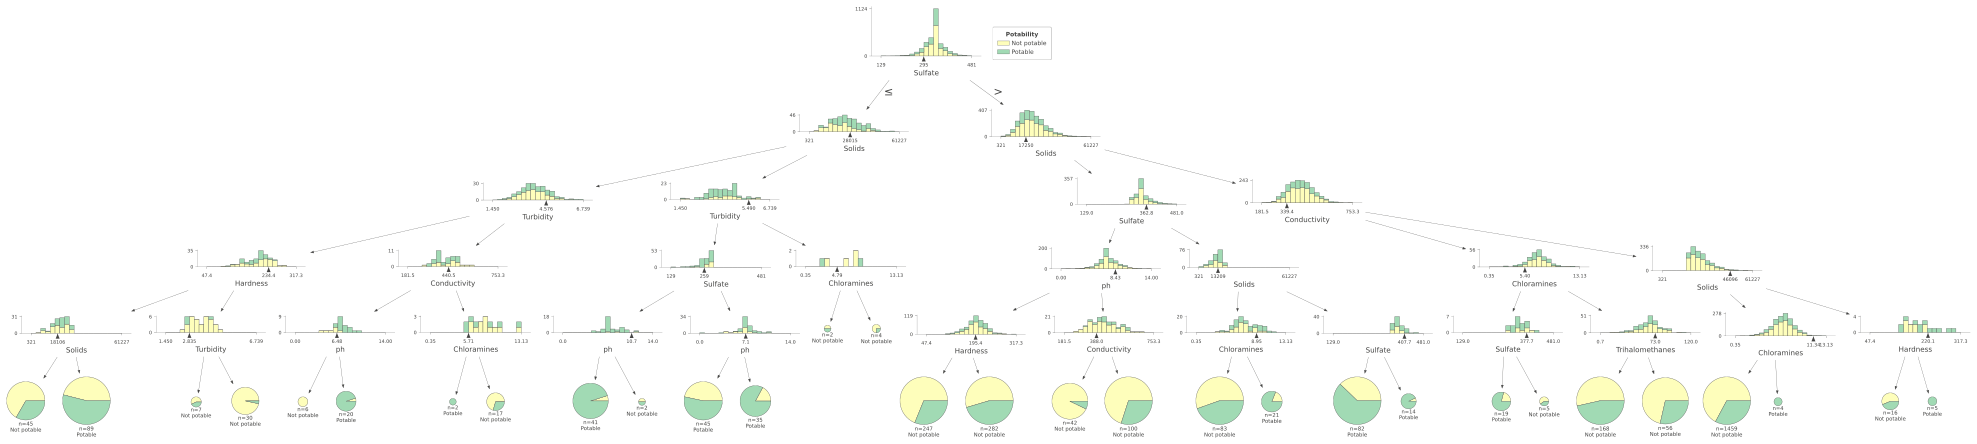

In [39]:
feature_names = list(features)
class_names = ['Not potable', 'Potable']

viz = dtreeviz.model(tree8, x_train, y_train, target_name='Potability',
                     feature_names=feature_names, class_names=class_names)
viz.view(scale=0.8, fontname='DejaVu Sans')

Για να διαβάσουμε τους κανόνες πιο εύκολα, τους τυπώνουμε και σε μορφή κειμένου:

In [40]:
print(export_text(tree8, feature_names=feature_names, class_names=class_names))

|--- Sulfate <= 294.90
|   |--- Solids <= 28015.32
|   |   |--- Turbidity <= 4.58
|   |   |   |--- Hardness <= 234.37
|   |   |   |   |--- Solids <= 18105.57
|   |   |   |   |   |--- class: Not potable
|   |   |   |   |--- Solids >  18105.57
|   |   |   |   |   |--- class: Potable
|   |   |   |--- Hardness >  234.37
|   |   |   |   |--- Turbidity <= 2.84
|   |   |   |   |   |--- class: Not potable
|   |   |   |   |--- Turbidity >  2.84
|   |   |   |   |   |--- class: Not potable
|   |   |--- Turbidity >  4.58
|   |   |   |--- Conductivity <= 440.49
|   |   |   |   |--- ph <= 6.48
|   |   |   |   |   |--- class: Not potable
|   |   |   |   |--- ph >  6.48
|   |   |   |   |   |--- class: Potable
|   |   |   |--- Conductivity >  440.49
|   |   |   |   |--- Chloramines <= 5.71
|   |   |   |   |   |--- class: Potable
|   |   |   |   |--- Chloramines >  5.71
|   |   |   |   |   |--- class: Not potable
|   |--- Solids >  28015.32
|   |   |--- Turbidity <= 5.49
|   |   |   |--- Sulfate <= 258.

### Συμπεράσματα

Το δέντρο κάνει το πολύ 5 ερωτήσεις για κάθε νερό. Η πρώτη ερώτηση (ρίζα) είναι αν τα θειικά (Sulfate) είναι κάτω από 294.9.

- Sulfate κάτω από 294.9: αν τα διαλυμένα στερεά (Solids) είναι πάνω από 28015 και η θολότητα (Turbidity) έως 5.49, το νερό είναι κυρίως πόσιμο.
- Sulfate πάνω από 294.9: αν τα στερεά είναι κάτω από 17250 και τα θειικά πάνω από 362.8, το νερό είναι συνήθως πόσιμο. Στις υπόλοιπες περιπτώσεις είναι κυρίως μη πόσιμο.

Τα χαρακτηριστικά που χρησιμοποιεί περισσότερο το δέντρο είναι τα Sulfate, Solids και Turbidity. Οι κανόνες δεν ταιριάζουν πάντα με τα όρια του ΠΟΥ, όπως είδαμε και στα Ερωτήματα 2 και 3.

## Ερώτημα 9 – Πρόβλεψη για ένα τυχαίο παράδειγμα


In [41]:
rng = np.random.default_rng(seed)
i = rng.integers(len(x_test))
sample = x_test[i]

print('Τιμές του δείγματος:')
display(pd.Series(sample, index=feature_names).round(3).to_frame('Τιμή'))
print('Πρόβλεψη δέντρου:', class_names[tree8.predict([sample])[0]])
print('Πραγματική τιμή :', class_names[y_test[i]])

Τιμές του δείγματος:


,Τιμή
ph,6.150
Hardness,188.413
Solids,8406.723
Chloramines,7.745
Sulfate,358.592
Conductivity,449.359
Organic_carbon,13.220
Trihalomethanes,52.957
Turbidity,3.444


Πρόβλεψη δέντρου: Not potable
Πραγματική τιμή : Potable


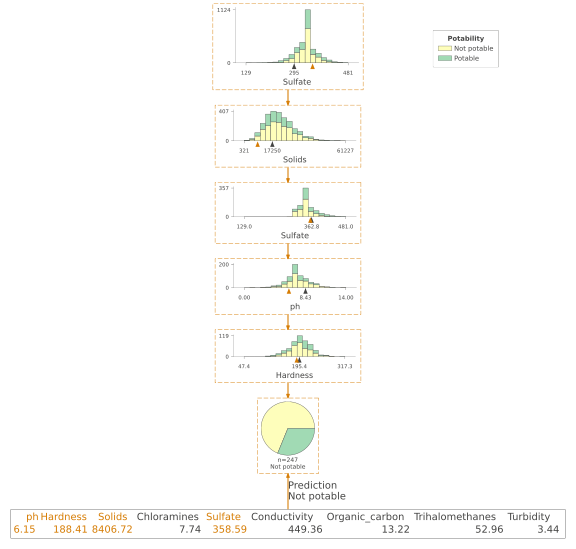

In [42]:
viz.view(x=sample, show_just_path=True, scale=0.9, fontname='DejaVu Sans')

In [43]:
print(viz.explain_prediction_path(sample))

ph < 8.43
Hardness < 195.43
Solids < 17250.13
294.9 <= Sulfate  < 362.79



### Συμπέρασμα

Το δείγμα περνάει από 5 ερωτήσεις (Sulfate, Solids, Sulfate ξανά, ph, Hardness) και καταλήγει σε φύλλο όπου τα περισσότερα νερά είναι μη πόσιμα. Γι' αυτό το δέντρο προβλέπει **μη πόσιμο**.

Στην πραγματικότητα το νερό είναι πόσιμο, άρα το δέντρο έκανε λάθος. Είναι όμως το «ακίνδυνο» λάθος: η συσκευή θα μας έλεγε να μην πιούμε ένα νερό που ήταν καλό.

## Ερώτημα 10 – Σημαντικότητα χαρακτηριστικών (feature importance)


Καλύτερος συνδυασμός συνολικά:


,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV Accuracy,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
0,gini,None,2,1,None,0.0,0.581739,1.0,1.0,1.0,0.628049,0.522059,0.554688


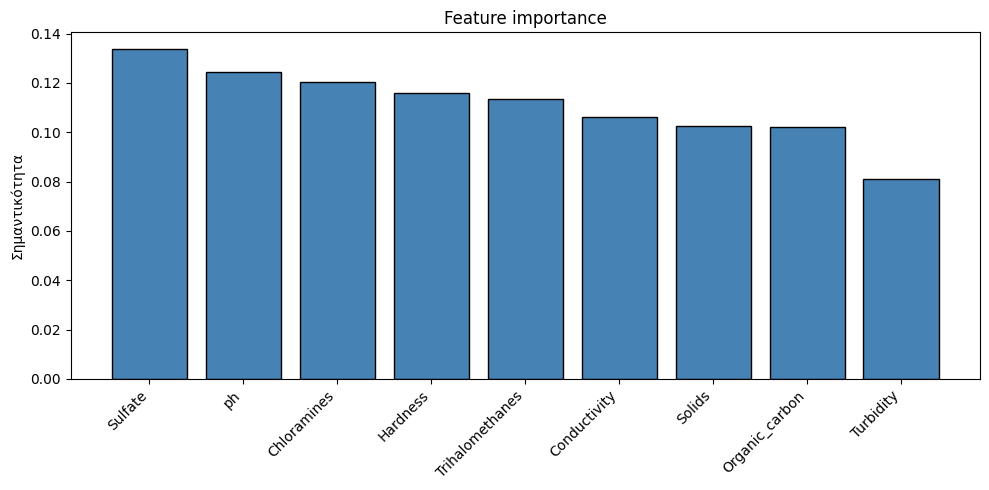

,Σημαντικότητα
Sulfate,0.1338
ph,0.1243
Chloramines,0.1202
Hardness,0.1159
Trihalomethanes,0.1135
Conductivity,0.1061
Solids,0.1027
Organic_carbon,0.1022
Turbidity,0.0812


In [44]:
best = results.loc[results['Test Accuracy'].idxmax()]
print('Καλύτερος συνδυασμός συνολικά:')
display(best.to_frame().T.round(4))

tree10 = DecisionTreeClassifier(**get_params(best))
tree10.fit(x_train, y_train)

importance = pd.Series(tree10.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(importance.index, importance.values, color='steelblue', edgecolor='black')
plt.title('Feature importance')
plt.ylabel('Σημαντικότητα')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

importance.round(4).to_frame('Σημαντικότητα')

### Ποια 5 χαρακτηριστικά θα έπρεπε να εξάγει η συσκευή;

Το καλύτερο δέντρο στο test είναι αυτό χωρίς όριο βάθους (test accuracy 0.628). Σύμφωνα με αυτό, τα 5 πιο σημαντικά χαρακτηριστικά είναι: **Sulfate, ph, Chloramines, Hardness και Trihalomethanes**. Αυτές τις 5 αναλύσεις θα έπρεπε να κάνει η συσκευή, γιατί βοήθησαν περισσότερο το δέντρο να ξεχωρίσει το πόσιμο από το μη πόσιμο νερό.

Οι διαφορές στη σημαντικότητα όμως είναι μικρές (από 0.08 έως 0.13), και το δέντρο αυτό κάνει overfitting. Άρα η επιλογή δεν είναι πολύ σίγουρη.

## Ερώτημα 11 – Τι είναι πιο σημαντικό;

Πιο σημαντικό είναι να μη λέει «πόσιμο» για νερό που δεν είναι πόσιμο. Αν η συσκευή κάνει αυτό το λάθος, κάποιος θα πιει επικίνδυνο νερό. Το αντίθετο λάθος να πει «μη πόσιμο» για καλό νερό απλώς μας κάνει να πετάξουμε ένα καλό νερό.

Άρα θέλουμε, όταν το μοντέλο λέει «πόσιμο», να έχει δίκιο. Η κατάλληλη μετρική είναι η **precision της κλάσης «πόσιμο»**: από όσες φορές είπε «πόσιμο», πόσες είχε δίκιο.

Precision (πόσιμο): 0.5556


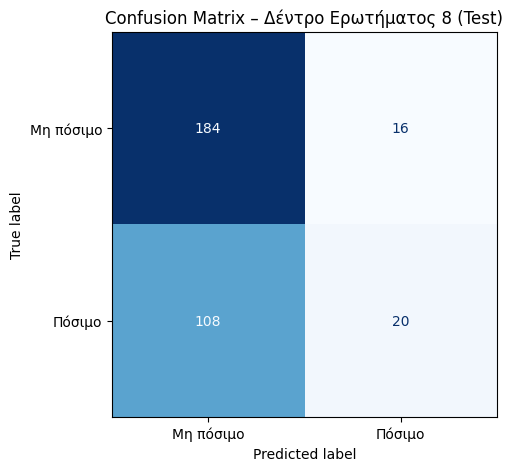

In [45]:
y_pred8 = tree8.predict(x_test)
print('Precision (πόσιμο):', round(precision_score(y_test, y_pred8), 4))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred8),
                       display_labels=['Μη πόσιμο', 'Πόσιμο']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix – Δέντρο Ερωτήματος 8 (Test)')
plt.show()

### Συμπέρασμα

Το δέντρο του Ερωτήματος 8 είπε «πόσιμο» 36 φορές: τις 20 είχε δίκιο και τις 16 ήταν λάθος (μη πόσιμο νερό). Άρα precision = 0.56.

Το δέντρο είναι προσεκτικό, γιατί σπάνια λέει πόσιμο. Όμως σχεδόν οι μισοί από τους «πόσιμο» χαρακτηρισμούς του είναι λάθος, οπότε δεν είναι αρκετά αξιόπιστο για πραγματική συσκευή.